# CatBoost

## Clasificador

In [1]:
import pandas as pd

df = pd.read_csv(
    "http://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None,
    names=[
        'age', 'workclass', 'fnlwgt', 'education', 'education-num',
        'marital-status', 'occupation', 'relationship','race', 'sex',
        'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
        ],
    na_values=' ?'
    )

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [3]:
df.isnull().sum().sort_values(ascending=False)

occupation        1843
workclass         1836
native-country     583
fnlwgt               0
education            0
education-num        0
age                  0
marital-status       0
relationship         0
sex                  0
race                 0
capital-gain         0
capital-loss         0
hours-per-week       0
income               0
dtype: int64

In [4]:
df = df.fillna(value="Unknown")

In [5]:
df['workclass'].unique()

array([' State-gov', ' Self-emp-not-inc', ' Private', ' Federal-gov',
       ' Local-gov', 'Unknown', ' Self-emp-inc', ' Without-pay',
       ' Never-worked'], dtype=object)

In [6]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

Para que funcione el procesamiento nativo de variables categóricas, es necesario convertir estas variables de tipo **object** (o **str**) a tipo **category**:

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop('income', axis=1)
y = df['income']

orden = [
    ' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th', ' 10th',' 11th', ' 12th',
    ' HS-grad',' Some-college', ' Assoc-acdm', ' Assoc-voc', ' Bachelors', ' Masters',
    ' Prof-school', ' Doctorate'
         ]
X['education'] = pd.Categorical(X['education'], categories=orden, ordered=True)

categorical_features = X.select_dtypes(include='object').columns.to_list()+['education']
X[categorical_features] = X[categorical_features].astype('category')

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
    )

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

In [8]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             32561 non-null  int64   
 1   workclass       32561 non-null  category
 2   fnlwgt          32561 non-null  int64   
 3   education       32561 non-null  category
 4   education-num   32561 non-null  int64   
 5   marital-status  32561 non-null  category
 6   occupation      32561 non-null  category
 7   relationship    32561 non-null  category
 8   race            32561 non-null  category
 9   sex             32561 non-null  category
 10  capital-gain    32561 non-null  int64   
 11  capital-loss    32561 non-null  int64   
 12  hours-per-week  32561 non-null  int64   
 13  native-country  32561 non-null  category
dtypes: category(8), int64(6)
memory usage: 1.7 MB


Se va a entrenar un modelo sin sintonizar hiperparámetros:

In [9]:
import time

from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    cat_features=categorical_features,
    iterations=200,         # Número de iteraciones (árboles)
    boosting_type='Plain',  # Para datasets pequeños, 'Plain' es más rápido y preciso
    auto_class_weights='Balanced',  # Ajusta automáticamente los pesos de las clases
    thread_count=-1,        # Utiliza todos los hilos físicos y lógicos
    verbose=0,
    random_state=1
)

inicio = time.time()
cat_model.fit(
    X_train,
    y_train,
    verbose=0
)
fin = time.time()
tiempo_ejecucion = fin - inicio

print(f'Train score: {cat_model.score(X_train, y_train):.3f}')
print(f'Test score: {cat_model.score(X_test, y_test):.3f}')
print(f'Tiempo de ejecución: {tiempo_ejecucion:.2f} segundos')

Train score: 0.851
Test score: 0.842
Tiempo de ejecución: 24.21 segundos


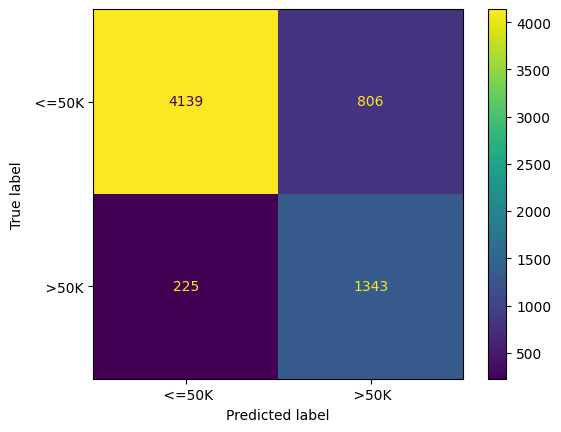

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    cat_model, 
    X_test, 
    y_test, 
    display_labels=le.classes_
    );

In [11]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, 
    cat_model.predict(X_test), 
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.95      0.84      0.89      4945
        >50K       0.62      0.86      0.72      1568

    accuracy                           0.84      6513
   macro avg       0.79      0.85      0.81      6513
weighted avg       0.87      0.84      0.85      6513



Ahora se va a sintonizar:

In [12]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_cat = {
    'iterations': randint(50, 400),
    'depth': randint(4, 8),
    'learning_rate': loguniform(0.01, 0.3),
    'l2_leaf_reg': loguniform(1e-3, 10),
    'subsample': uniform(0.6, 0.4),
    'colsample_bylevel': uniform(0.6, 0.4),
    'border_count': randint(32, 128),
    'random_strength': loguniform(1e-3, 10),
}

cat_base = CatBoostClassifier(
    boosting_type='Plain',
    auto_class_weights='Balanced',
    thread_count=-1,
    verbose=0,
    random_state=1
)

rs_cat = RandomizedSearchCV(
    estimator=cat_base,
    param_distributions=dist_cat,
    n_iter=20,
    scoring='f1_weighted',
    cv=3,
    random_state=1,
    n_jobs=1
)

inicio = time.time()
rs_cat.fit(
    X_train, 
    y_train, 
    cat_features=categorical_features
    )
fin = time.time()
tiempo_ejecucion = fin - inicio

print(f'Mejor F1 ponderado: {rs_cat.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_cat.best_params_}')
print(f'Train score: {rs_cat.score(X_train, y_train):.3f}')
print(f'Test score: {rs_cat.score(X_test, y_test):.3f}')
print(f'Tiempo de ejecución: {tiempo_ejecucion:.2f} segundos')

Mejor F1 ponderado: 0.848
Parámetros óptimos: {'border_count': 119, 'colsample_bylevel': np.float64(0.8296470421968052), 'depth': 7, 'iterations': 398, 'l2_leaf_reg': np.float64(0.22762614721505595), 'learning_rate': np.float64(0.10805079005806441), 'random_strength': np.float64(0.002566479001644615), 'subsample': np.float64(0.7656223951278274)}
Train score: 0.881
Test score: 0.853
Tiempo de ejecución: 1257.86 segundos


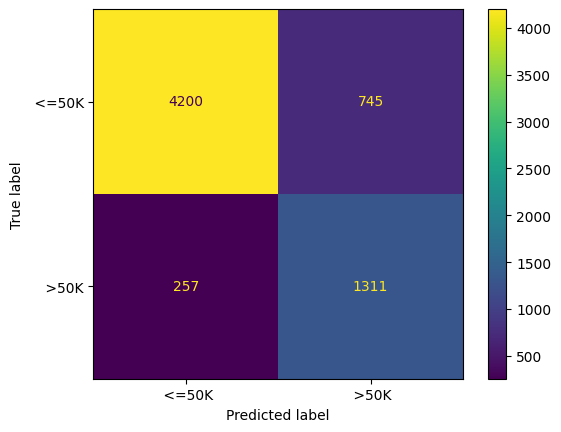

In [13]:
ConfusionMatrixDisplay.from_estimator(
    rs_cat.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [14]:
print(classification_report(
    y_test,
    rs_cat.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.94      0.85      0.89      4945
        >50K       0.64      0.84      0.72      1568

    accuracy                           0.85      6513
   macro avg       0.79      0.84      0.81      6513
weighted avg       0.87      0.85      0.85      6513



Este modelo también da información acerca de la importancia relativa de cada característica:

In [15]:
cat_features = pd.DataFrame({
    'Feature': rs_cat.best_estimator_.feature_names_,
    'Importance': rs_cat.best_estimator_.feature_importances_
})

cat_features.sort_values('Importance', ascending=False)

,Feature,Importance
0,age,14.616980
6,occupation,10.941088
10,capital-gain,10.755177
2,fnlwgt,9.432142
5,marital-status,8.899575
12,hours-per-week,8.050024
7,relationship,7.863898
4,education-num,6.446119
3,education,5.693870
1,workclass,4.382556


## Regresor

In [16]:
from pathlib import Path

data_dir = Path().resolve().parent / "data" / "raw"
data_name = "home_data.csv"
filepath = data_dir / data_name

df = pd.read_csv(filepath)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [17]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=['id', 'date'], axis=1)

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
    )

print(X_train.shape)
print(X_test.shape)

(17290, 18)
(4323, 18)


In [18]:
from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

cat_model = CatBoostRegressor(
    iterations=1000,         # Número de iteraciones (árboles)
    boosting_type='Plain',  # Para datasets pequeños, 'Plain' es más rápido y preciso
    thread_count=-1,        # Utiliza todos los hilos físicos y lógicos
    verbose=0,
    random_state=1
)

inicio = time.time()
cat_model.fit(
    X_train,
    y_train,
    verbose=0
)
fin = time.time()
tiempo_ejecucion = fin - inicio

train_score = root_mean_squared_error(y_train, cat_model.predict(X_train))
test_score = root_mean_squared_error(y_test, cat_model.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')
print(f'Tiempo de ejecución: {tiempo_ejecucion:.2f} segundos')

Train score: 69219.796
Test score: 141869.774
Tiempo de ejecución: 4.01 segundos


In [21]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_cat = {
    'iterations': randint(50, 400),
    'depth': randint(4, 8),
    'learning_rate': loguniform(0.01, 0.3),
    'l2_leaf_reg': loguniform(1e-3, 10),
    'subsample': uniform(0.6, 0.4),
    'colsample_bylevel': uniform(0.6, 0.4),
    'border_count': randint(32, 128),
    'random_strength': loguniform(1e-3, 10),
}

cat_base = CatBoostRegressor(
    boosting_type='Plain',
    thread_count=-1,
    verbose=0,
    random_state=1
)

rs_cat = RandomizedSearchCV(
    estimator=cat_base,
    param_distributions=dist_cat,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=1,
    n_jobs=-1
)

inicio = time.time()
rs_cat.fit(X_train, y_train)
fin = time.time()
tiempo_ejecucion = fin - inicio

print(f'Mejor RMSE: {-rs_cat.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_cat.best_params_}')
print(f'Train RMSE: {-rs_cat.score(X_train, y_train):.3f}')
print(f'Test RMSE: {-rs_cat.score(X_test, y_test):.3f}')
print(f'Tiempo de ejecución: {tiempo_ejecucion:.2f} segundos')

Mejor RMSE: 113021.290
Parámetros óptimos: {'border_count': 119, 'colsample_bylevel': np.float64(0.8296470421968052), 'depth': 7, 'iterations': 398, 'l2_leaf_reg': np.float64(0.22762614721505595), 'learning_rate': np.float64(0.10805079005806441), 'random_strength': np.float64(0.002566479001644615), 'subsample': np.float64(0.7656223951278274)}
Train RMSE: 63258.387
Test RMSE: 148524.666
Tiempo de ejecución: 17.44 segundos


In [22]:
cat_features = pd.DataFrame({
    'Feature': rs_cat.best_estimator_.feature_names_,
    'Importance': rs_cat.best_estimator_.feature_importances_
})

cat_features.sort_values('Importance', ascending=False)

,Feature,Importance
14,lat,29.109625
2,sqft_living,17.207777
15,long,12.745166
8,grade,11.742652
5,waterfront,4.227768
13,zipcode,4.218117
16,sqft_living15,4.009134
11,yr_built,3.508842
6,view,3.361663
9,sqft_above,2.163338
